In [4]:
from google.colab import drive
import os
import duckdb
import pandas as pd


drive.mount('/content/drive')


DATA_PATH = '/content/drive/MyDrive/hackthon'
con = duckdb.connect()


files = sorted(os.listdir(DATA_PATH))
print(f"Total Files Found ({len(files)}):", files)


Mounted at /content/drive
Total Files Found (8): ['batteries.csv', 'city_daily_context.csv', 'fleet_partners.csv', 'riders.csv', 'station_hourly_status.csv', 'stations.csv', 'support_tickets.csv', 'swap_events.csv']


In [5]:
print("=== swap_events.csv COLUMNS ===")
cols = con.execute(f"""
    DESCRIBE SELECT * FROM read_csv('{DATA_PATH}/swap_events.csv', delim=',', header=true, auto_detect=true, strict_mode=false, null_padding=true, ignore_errors=true)
""").df()[['column_name', 'column_type']]
print(cols.to_string(index=False))

print("\n=== SAMPLE 3 ROWS ===")
display(con.execute(f"""
    SELECT * FROM read_csv('{DATA_PATH}/swap_events.csv', delim=',', header=true, auto_detect=true, strict_mode=false, null_padding=true, ignore_errors=true) LIMIT 3
""").df())


=== swap_events.csv COLUMNS ===
           column_name column_type
              event_id     VARCHAR
              rider_id     VARCHAR
            station_id     VARCHAR
              event_ts   TIMESTAMP
            event_type     VARCHAR
           attempt_seq      BIGINT
        queue_wait_sec      BIGINT
         battery_in_id     VARCHAR
        battery_out_id     VARCHAR
            soc_in_pct      DOUBLE
            soh_in_pct      DOUBLE
           soc_out_pct      DOUBLE
           soh_out_pct      DOUBLE
    km_since_last_swap      DOUBLE
           tariff_code     VARCHAR
        list_price_inr      DOUBLE
          discount_inr      DOUBLE
    amount_charged_inr      DOUBLE
          payment_mode     VARCHAR
energy_to_recharge_kwh      DOUBLE
      station_firmware     VARCHAR
             sync_mode     VARCHAR

=== SAMPLE 3 ROWS ===


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime


Question 1: Monitoring Network Performance (Jan 2024 to Jun 2025)

This query establishes a database view that can be reused that links together swap_events.csv and stations.csv. This allows us to see how the network has performed on a monthly basis. It calculates the total number of swap attempts, completed swaps, service failure/abandonment rate, average revenue generated per swap, Net Contribution Margin per swap (revenue minus electricity recharge) and average queue times.

In [6]:
con.execute(f"""
    CREATE OR REPLACE VIEW swaps AS
    SELECT * FROM read_csv('{DATA_PATH}/swap_events.csv', delim=',', header=true, auto_detect=true, strict_mode=false, null_padding=true, ignore_errors=true)
""")

print("=== EVENT TYPES BREAKDOWN ===")
display(con.execute("SELECT event_type, COUNT(*) AS cnt FROM swaps GROUP BY 1 ORDER BY cnt DESC").df())

print("\n=== Q1: MONTHLY NETWORK PERFORMANCE & MARGIN TREND ===")
q1_df = con.execute(f"""
    SELECT
        DATE_TRUNC('month', s.event_ts) AS month,
        COUNT(*) AS total_attempts,
        SUM(CASE WHEN s.event_type = 'swap_completed' THEN 1 ELSE 0 END) AS completed_swaps,
        ROUND(100.0 * SUM(CASE WHEN s.event_type != 'swap_completed' THEN 1 ELSE 0 END) / COUNT(*), 2) AS failure_rate_pct,
        ROUND(AVG(CASE WHEN s.event_type = 'swap_completed' THEN s.amount_charged_inr END), 2) AS avg_rev_per_swap,
        ROUND(AVG(CASE WHEN s.event_type = 'swap_completed' THEN (s.amount_charged_inr - (s.energy_to_recharge_kwh * st.grid_tariff_inr_kwh)) END), 2) AS avg_margin_per_swap,
        ROUND(AVG(s.queue_wait_sec), 1) AS avg_queue_sec
    FROM swaps s
    LEFT JOIN '{DATA_PATH}/stations.csv' st ON s.station_id = st.station_id
    GROUP BY 1
    ORDER BY 1
""").df()
display(q1_df)


=== EVENT TYPES BREAKDOWN ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,cnt
0,swap_completed,3645809
1,failed_no_charged_battery,134389
2,abandoned_queue,68533
3,cancelled_by_rider,16712
4,failed_system_error,11570



=== Q1: MONTHLY NETWORK PERFORMANCE & MARGIN TREND ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_attempts,completed_swaps,failure_rate_pct,avg_rev_per_swap,avg_margin_per_swap,avg_queue_sec
0,2024-01-01,110348,105490.0,4.40,59.90,37.90,242.3
1,2024-02-01,111531,106582.0,4.44,59.93,38.03,243.5
2,2024-03-01,123900,118444.0,4.40,59.89,38.17,242.2
3,2024-04-01,131818,122836.0,6.81,60.00,38.41,243.3
4,2024-05-01,146278,128328.0,12.27,59.92,38.59,242.7
5,2024-06-01,148888,133743.0,10.17,59.84,38.80,242.3
6,2024-07-01,158688,151824.0,4.33,65.07,44.22,243.1
7,2024-08-01,172295,164931.0,4.27,65.02,44.38,243.3
8,2024-09-01,195885,187302.0,4.38,64.68,44.23,242.9
9,2024-10-01,229901,219838.0,4.38,66.31,46.09,243.1


**Key Insights – Q1**

1. Increased Volume & Revenue
There has been an increase in completed swaps from 105,490 in January 2024 to 307,259 in June 2025.
Average revenue generated per completed swap has increased from ₹59.90 in January 2024 to ₹65.07 in July 2024. For the latter months, average revenue per completed swap was around ₹65.
2. Increased Abandonment
On average there were around 4.2% – 4.4% abandoned attempts per month.

In May 2024 and May 2025 abandoned attempts were 12.27% and 9.91% respectively.
June 2025 had 8.55% abandoned attempts.

3. Key Reasons for Abandonment
Looking at the reasons for the 231,204 abandoned attempts:
No charged battery – 134,389 (58.1%)
Abandoned Queue – 68,533 (29.6%)
Cancelled by rider – 16,712 (7.2%)
System error – 11,570 (5.0%)

The main areas to improve would be battery availability and queues.

4. Revenue & Energy Contribution
From January 2024 to June 2025 average revenue per completed swap has increased from ₹59.90 to ₹64.98.
Average energy contribution per completed swap has also increased from ₹37.90 to ₹47.96.
Average queue wait times have remained consistent at around 242-244 seconds.

Energy contribution is calculated using revenue minus the cost of recharging electricity. This does not include rent, maintenance or battery depreciation.

5. Business Recommendations
Ensure enough charged batteries are available at busy stations.
Improve forecasting of demand during busy seasons.
Reduce abandonment by improving capacity within stations and battery availability.
Monitor abandonment during busy seasons.
Monitor electricity costs and revenue to improve energy contribution.

6. Conclusion
VoltRelay Energy has seen a large increase in completed swaps from January 2024 to June 2025. However, there are still issues with battery shortages and queue abandonment. By improving battery availability, planning and queue management, this can increase the number of successful swaps and improve customer experience.

**Question 2:** Service Failures and Customer Experience

The graph shows the variation of wait time in queue, failed_no_charged_battery and abandonment in queue across different hours in the day, vehicle class (2W vs 3W) and city. We can get an understanding of whether the service failures are occurring throughout the network or only in certain areas.

In [22]:

# ============================================================
# QUESTION 2: SERVICE FAILURES & CUSTOMER EXPERIENCE
# ============================================================

# Q2A: HOURLY FAILURE AND QUEUE PATTERN

print("=== Q2A: HOURLY FAILURE AND QUEUE PATTERN ===")

display(con.execute(f"""
    SELECT
        EXTRACT(HOUR FROM event_ts) AS hour,
        COUNT(*) AS total_attempts,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS stockout_fail_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type = 'abandoned_queue'
            ) / COUNT(*), 2
        ) AS abandon_pct,
        ROUND(AVG(queue_wait_sec), 1) AS avg_wait_sec
    FROM swaps
    GROUP BY 1
    ORDER BY 1
""").df())


# Q2B: VEHICLE CLASS AND CITY PERFORMANCE

print("\n=== Q2B: VEHICLE CLASS AND CITY PERFORMANCE ===")

display(con.execute(f"""
    SELECT
        st.city,
        r.vehicle_class,
        COUNT(*) AS total_attempts,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE s.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS total_fail_pct,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE s.event_type = 'failed_no_charged_battery'
            ) / COUNT(*), 2
        ) AS stockout_pct,
        ROUND(AVG(s.queue_wait_sec), 1) AS avg_wait_sec
    FROM swaps s
    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id
    JOIN '{DATA_PATH}/riders.csv' r
        ON s.rider_id = r.rider_id
    GROUP BY 1, 2
    ORDER BY total_fail_pct DESC
""").df())


# Q2C: TOP 10 WORST PERFORMING STATIONS

print("\n=== Q2C: TOP 10 WORST PERFORMING STATIONS ===")

display(con.execute(f"""
    SELECT
        st.station_id,
        st.city,
        st.location_type,
        st.charger_generation,
        st.expansion_wave,
        COUNT(*) AS total_attempts,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE s.event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS fail_rate_pct,
        ROUND(AVG(s.queue_wait_sec), 1) AS avg_wait_sec
    FROM swaps s
    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id
    GROUP BY 1, 2, 3, 4, 5
    ORDER BY fail_rate_pct DESC
    LIMIT 10
""").df())


=== Q2A: HOURLY FAILURE AND QUEUE PATTERN ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,hour,total_attempts,stockout_fail_pct,abandon_pct,avg_wait_sec
0,0,23043,3.21,1.64,243.9
1,1,23482,3.08,1.70,245.1
2,2,25536,3.25,1.63,242.6
3,3,28822,2.82,1.65,243.6
4,4,31193,2.91,1.50,241.4
5,5,28510,2.99,1.67,243.7
6,6,62020,3.12,1.63,242.7
7,7,66889,3.01,1.66,243.7
8,8,171129,3.26,1.69,242.9
9,9,232933,3.22,1.65,242.6



=== Q2B: VEHICLE CLASS AND CITY PERFORMANCE ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,vehicle_class,total_attempts,total_fail_pct,stockout_pct,avg_wait_sec
0,Jaipur,3W,51299,12.33,7.81,243.0
1,Delhi NCR,3W,77932,11.42,7.06,242.8
2,Hyderabad,3W,72143,11.10,6.98,242.1
3,Pune,3W,63755,9.58,5.94,242.8
4,Bengaluru,3W,90887,9.31,5.60,242.8
5,Mumbai,3W,68001,8.94,5.40,243.4
6,Jaipur,2W,436335,7.32,4.42,243.3
7,Delhi NCR,2W,690981,6.89,4.11,242.7
8,Hyderabad,2W,639787,6.19,3.63,242.9
9,Pune,2W,489155,4.39,2.39,243.0



=== Q2C: TOP 10 WORST PERFORMING STATIONS ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,station_id,city,location_type,charger_generation,expansion_wave,total_attempts,fail_rate_pct,avg_wait_sec
0,STN-DEL-037,Delhi NCR,commercial_hub,Gen1,Launch,30838,9.08,242.6
1,STN-DEL-048,Delhi NCR,market,Gen1,Launch,34646,8.98,244.0
2,STN-JAI-137,Jaipur,commercial_hub,Gen1,Launch,44371,8.75,242.8
3,STN-JAI-142,Jaipur,commercial_hub,Gen1,Launch,33319,8.75,244.3
4,STN-JAI-141,Jaipur,commercial_hub,Gen1,Launch,45594,8.73,243.7
5,STN-DEL-045,Delhi NCR,commercial_hub,Gen1,Launch,32237,8.72,243.1
6,STN-JAI-136,Jaipur,transit_hub,Gen1,Launch,29340,8.71,241.9
7,STN-JAI-138,Jaipur,market,Gen1,Launch,48945,8.67,243.4
8,STN-DEL-040,Delhi NCR,market,Gen1,Launch,40335,8.65,242.7
9,STN-DEL-050,Delhi NCR,commercial_hub,Gen1,Launch,47060,8.61,242.0


In [20]:
display(con.execute("DESCRIBE swaps").df())

,column_name,column_type,null,key,default,extra
0,event_id,VARCHAR,YES,None,None,None
1,rider_id,VARCHAR,YES,None,None,None
2,station_id,VARCHAR,YES,None,None,None
3,event_ts,TIMESTAMP,YES,None,None,None
4,event_type,VARCHAR,YES,None,None,None
5,attempt_seq,BIGINT,YES,None,None,None
6,queue_wait_sec,BIGINT,YES,None,None,None
7,battery_in_id,VARCHAR,YES,None,None,None
8,battery_out_id,VARCHAR,YES,None,None,None
9,soc_in_pct,DOUBLE,YES,None,None,None


In [21]:
print("STATIONS COLUMNS")
display(con.execute(f"DESCRIBE SELECT * FROM '{DATA_PATH}/stations.csv'").df())

print("RIDERS COLUMNS")
display(con.execute(f"DESCRIBE SELECT * FROM '{DATA_PATH}/riders.csv'").df())

STATIONS COLUMNS


,column_name,column_type,null,key,default,extra
0,station_id,VARCHAR,YES,None,None,None
1,city,VARCHAR,YES,None,None,None
2,zone,VARCHAR,YES,None,None,None
3,latitude,DOUBLE,YES,None,None,None
4,longitude,DOUBLE,YES,None,None,None
5,location_type,VARCHAR,YES,None,None,None
6,host_type,VARCHAR,YES,None,None,None
7,commissioned_date,DATE,YES,None,None,None
8,decommissioned_date,DATE,YES,None,None,None
9,expansion_wave,VARCHAR,YES,None,None,None


RIDERS COLUMNS


,column_name,column_type,null,key,default,extra
0,rider_id,VARCHAR,YES,None,None,None
1,partner_id,VARCHAR,YES,None,None,None
2,vehicle_class,VARCHAR,YES,None,None,None
3,vehicle_model,VARCHAR,YES,None,None,None
4,home_zone,VARCHAR,YES,None,None,None
5,signup_date,DATE,YES,None,None,None
6,signup_channel,VARCHAR,YES,None,None,None
7,plan_type,VARCHAR,YES,None,None,None
8,declared_shift,VARCHAR,YES,None,None,None
9,age_band,VARCHAR,YES,None,None,None


**Insights:**

The completion rate for 3W vehicles is lower than that of 2W vehicles across all six cities. The highest completion rate was observed in Jaipur 3W, Delhi NCR 3W and Hyderabad 3W with 12.33%, 11.42% and 11.10% respectively. The lowest was observed in Mumbai 2W with a 3.79% completion rate.

Peak demand was observed in the evening between 19-22. The maximum number of swipe attempts were recorded at 19 and 20 with over 447k swipes per hour. Between these hours, the failure rate of stockouts increased to 3.91%-3.95%. Alongside this queue abandonment increased to 1.90%-1.94%.

All the top 10 worst performing stations are Gen1 chargers within the original launch wave of expansion. These stations can be found in Delhi NCR and Jaipur. They are located in mostly commercial areas and market areas. Completion rates varied between 8.61%-9.08%.

**Question 3:** Station and Geography Analysis

This analysis combines data from all of these files (stations.csv, station_hourly_status.csv, swap_events.csv and support_tickets.csv) to understand how charger generation, expansion wave and location type affects charging times, cabinet temperatures, station usage and support tickets.

In [23]:

# ============================================================
# QUESTION 3: STATION & GEOGRAPHIC PATTERNS
# ============================================================

# Q3A: CHARGER GENERATION & EXPANSION WAVE PERFORMANCE

print("=== Q3A: CHARGER GENERATION & EXPANSION WAVE PERFORMANCE ===")

display(con.execute(f"""
    WITH hourly_agg AS (
        SELECT
            station_id,
            AVG(avg_charge_minutes) AS avg_charge_mins,
            AVG(cabinet_temp_c) AS avg_cabinet_temp,
            AVG(outage_minutes) AS avg_outage_mins_hr
        FROM '{DATA_PATH}/station_hourly_status.csv'
        GROUP BY station_id
    ),

    swap_agg AS (
        SELECT
            station_id,
            COUNT(*) AS total_attempts,
            SUM(
                CASE
                    WHEN event_type != 'swap_completed' THEN 1
                    ELSE 0
                END
            ) AS failed_attempts
        FROM swaps
        GROUP BY station_id
    )

    SELECT
        st.charger_generation,
        st.expansion_wave,
        COUNT(st.station_id) AS station_count,
        ROUND(AVG(h.avg_charge_mins), 1) AS avg_charge_mins,
        ROUND(AVG(h.avg_cabinet_temp), 1) AS avg_cabinet_temp,
        ROUND(AVG(h.avg_outage_mins_hr), 2) AS avg_outage_mins_hr,
        ROUND(
            100.0 * SUM(sw.failed_attempts) /
            NULLIF(SUM(sw.total_attempts), 0), 2
        ) AS fail_rate_pct

    FROM '{DATA_PATH}/stations.csv' st

    LEFT JOIN hourly_agg h
        ON st.station_id = h.station_id

    LEFT JOIN swap_agg sw
        ON st.station_id = sw.station_id

    GROUP BY 1, 2
    ORDER BY fail_rate_pct DESC
""").df())


# Q3B: CITY & LOCATION TYPE PERFORMANCE + SUPPORT TICKETS

print("\n=== Q3B: CITY & LOCATION TYPE PERFORMANCE + SUPPORT TICKETS ===")

display(con.execute(f"""
    WITH ticket_counts AS (
        SELECT
            station_id,
            COUNT(*) AS total_tickets,
            AVG(csat_score) AS avg_csat
        FROM '{DATA_PATH}/support_tickets.csv'
        GROUP BY station_id
    )

    SELECT
        st.city,
        st.location_type,
        COUNT(DISTINCT st.station_id) AS stations,
        ROUND(AVG(st.slots_2w), 1) AS avg_2w_slots,
        ROUND(AVG(st.slots_3w), 1) AS avg_3w_slots,
        ROUND(
            AVG(COALESCE(t.total_tickets, 0)), 1
        ) AS avg_tickets_per_station,
        ROUND(AVG(t.avg_csat), 2) AS avg_csat

    FROM '{DATA_PATH}/stations.csv' st

    LEFT JOIN ticket_counts t
        ON st.station_id = t.station_id

    GROUP BY 1, 2
    ORDER BY avg_tickets_per_station DESC
    LIMIT 12
""").df())


=== Q3A: CHARGER GENERATION & EXPANSION WAVE PERFORMANCE ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,charger_generation,expansion_wave,station_count,avg_charge_mins,avg_cabinet_temp,avg_outage_mins_hr,fail_rate_pct
0,Gen1,Launch,51,91.8,24.9,0.01,7.23
1,Gen2,Wave1_2024H2,23,64.4,24.1,0.01,4.99
2,Gen3,Wave2_2025H1,30,42.2,31.1,0.02,4.99
3,Gen2,Launch,41,64.2,24.8,0.02,4.80
4,Gen3,Wave1_2024H2,7,42.1,24.0,0.01,4.56



=== Q3B: CITY & LOCATION TYPE PERFORMANCE + SUPPORT TICKETS ===


,city,location_type,stations,avg_2w_slots,avg_3w_slots,avg_tickets_per_station,avg_csat
0,Jaipur,commercial_hub,7,13.7,1.4,520.7,3.57
1,Delhi NCR,commercial_hub,7,11.4,0.0,469.7,3.56
2,Hyderabad,market,7,15.4,4.0,406.4,3.55
3,Delhi NCR,market,11,13.1,2.4,373.4,3.57
4,Hyderabad,commercial_hub,8,11.5,1.0,372.9,3.61
5,Jaipur,transit_hub,1,8.0,6.0,368.0,3.53
6,Jaipur,market,4,13.0,1.0,314.5,3.50
7,Pune,commercial_hub,6,14.7,0.7,309.8,3.54
8,Mumbai,commercial_hub,8,13.5,2.5,298.3,3.52
9,Bengaluru,commercial_hub,10,12.0,2.0,288.6,3.59


**Key Insights – Question 3**

1. Gen1 Chargers Have Highest Non-Completion Rate

The average charging time for Gen1 Launch chargers was 91.8 minutes, with a high non-completion rate of 7.23%. Comparatively, Gen3 chargers had a low non-completion rate (4.56%) during Wave1, with an average charging time of 42.1 minutes. This shows that newer generations of chargers are performing well.

2. Highest Average Support Tickets at Jaipur and Delhi NCR

Average support tickets per station were highest in Jaipur commercial hubs (520.7) and Delhi NCR commercial hubs (469.7). However, the average capacity of 3W slots in these areas was very low (1.4 and 0.0). This could indicate an issue with capacity planning for 3W vehicles.

3. Newer Chargers Performing Well

Gen3 chargers have much lower average charging times than Gen1 chargers. However, Gen3 Wave2 had a higher non-completion rate at 4.99% versus Gen3 Wave1 at 4.56%. The generation of charger, where it has been deployed and the conditions the charger is operating in should be considered when planning future upgrades.

**Question 4:** Battery and Equipment Performance

Analysis of battery health (current_soh_pct), ride range provided (km_since_last_swap), number of swaps and early retirements by battery supplier, manufacturing lot and pack type to see any faulty hardware.

In [25]:

# ============================================================
# QUESTION 4: BATTERY AND EQUIPMENT PERFORMANCE
# ============================================================

# Q4A: BATTERY SUPPLIER & MANUFACTURING LOT HEALTH

print("=== Q4A: BATTERY SUPPLIER & MANUFACTURING LOT HEALTH ===")

display(con.execute(f"""
    SELECT
        supplier,
        manufacturing_lot,
        pack_type,
        COUNT(*) AS total_packs,

        ROUND(AVG(initial_soh_pct), 2) AS avg_init_soh,
        ROUND(AVG(current_soh_pct), 2) AS avg_curr_soh,

        ROUND(
            AVG(initial_soh_pct - current_soh_pct), 2
        ) AS soh_drop,

        SUM(
            CASE
                WHEN retired_date IS NOT NULL THEN 1
                ELSE 0
            END
        ) AS retired_packs,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN retired_date IS NOT NULL THEN 1
                    ELSE 0
                END
            ) / COUNT(*), 1
        ) AS retired_pct,

        MODE(retirement_reason) AS top_retire_reason

    FROM '{DATA_PATH}/batteries.csv'

    GROUP BY 1, 2, 3
    ORDER BY soh_drop DESC
""").df())


# Q4B: DELIVERED RANGE & SWAP BEHAVIOR BY SUPPLIER/LOT

print("\n=== Q4B: DELIVERED RANGE & SWAP BEHAVIOR BY SUPPLIER/LOT ===")

display(con.execute(f"""
    SELECT
        b.supplier,
        b.manufacturing_lot,
        b.pack_type,

        COUNT(s.event_id) AS completed_swaps,

        ROUND(
            AVG(s.km_since_last_swap), 1
        ) AS avg_km_delivered,

        ROUND(
            AVG(s.soh_in_pct), 2
        ) AS avg_soh_at_swap,

        ROUND(
            AVG(s.energy_to_recharge_kwh), 3
        ) AS avg_kwh_recharged

    FROM swaps s

    JOIN '{DATA_PATH}/batteries.csv' b
        ON s.battery_in_id = b.battery_id

    WHERE s.event_type = 'swap_completed'

    GROUP BY 1, 2, 3
    ORDER BY avg_km_delivered ASC
""").df())


=== Q4A: BATTERY SUPPLIER & MANUFACTURING LOT HEALTH ===


,supplier,manufacturing_lot,pack_type,total_packs,avg_init_soh,avg_curr_soh,soh_drop,retired_packs,retired_pct,top_retire_reason
0,Kyron,KY-2408,2W_2.1kWh,471,99.22,60.53,38.69,471.0,100.0,end_of_life
1,Kyron,KY-2407,2W_2.1kWh,452,99.17,60.51,38.66,452.0,100.0,end_of_life
2,Kyron,KY-2409,2W_2.1kWh,462,99.20,60.56,38.64,462.0,100.0,end_of_life
3,Kyron,KY-2407,3W_4.8kWh,28,99.16,68.73,30.43,24.0,85.7,end_of_life
4,Kyron,KY-2408,3W_4.8kWh,29,99.23,69.47,29.76,18.0,62.1,end_of_life
...,...,...,...,...,...,...,...,...,...,...
96,Cellora,CE-2309,3W_4.8kWh,19,99.23,86.77,12.46,0.0,0.0,None
97,Amptek,AM-2502,3W_4.8kWh,10,99.30,86.88,12.42,0.0,0.0,None
98,Amptek,AM-2505,3W_4.8kWh,14,99.14,86.74,12.41,0.0,0.0,None
99,Cellora,CE-2402,3W_4.8kWh,22,99.15,86.75,12.40,0.0,0.0,None



=== Q4B: DELIVERED RANGE & SWAP BEHAVIOR BY SUPPLIER/LOT ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,supplier,manufacturing_lot,pack_type,completed_swaps,avg_km_delivered,avg_soh_at_swap,avg_kwh_recharged
0,Kyron,KY-2408,2W_2.1kWh,242627,49.2,80.65,1.749
1,Kyron,KY-2407,2W_2.1kWh,232566,49.2,80.64,1.750
2,Kyron,KY-2409,2W_2.1kWh,237550,49.2,80.68,1.749
3,Amptek,AM-2501,2W_2.1kWh,48494,61.2,89.63,1.849
4,Cellora,CE-2303,2W_2.1kWh,67461,61.2,89.66,1.849
...,...,...,...,...,...,...,...
96,Cellora,CE-2501,3W_4.8kWh,6558,91.0,93.02,4.370
97,Cellora,CE-2411,3W_4.8kWh,6940,91.0,93.17,4.374
98,Cellora,CE-2309,3W_4.8kWh,7201,91.0,93.16,4.370
99,Amptek,AM-2407,3W_4.8kWh,7400,91.0,93.10,4.369


## Key Findings - Question 4: Battery & Equipment Performance

1. High Battery Degradation for Kyron 2W Manufacturing Lots

During the investigation into the battery performance, it was found that the Kyron manufacturing lots (KY-2407, KY-2408, KY-2409) had high degradation with an average degradation level of approximately 38.7%. The batteries had degraded from an initial state of health level of approximately 99.2% to a current state of health level of 60.5%. All 1,385 battery packs were retired with a retirement reason of end_of_life.

2. Low Range of Kyron 2W Batteries

The Kyron 2W batteries had an average range of 49.2km per battery swap, compared to the displayed Amptek and Cellora 2W lots with an average range of 61.2km. This is approximately 19.6% less range and the three Kyron lots have had 712,743 battery swaps completed.

3. Implications

A low range between charges could mean more frequent battery swaps will be needed which may cause increased demand at the swap stations. This could cause issues with the battery stock. It would appear that Kyron lots KY-2407, KY-2408 and KY-2409 should be looked into further to investigate any quality issues.

**QUESTION 5.** Pricing and Partner Economics:

The impact of tariff codes (Standard, Peak, Off-Peak, Partner) on pricing across the different cities are analysed. This report looks at fleet partner economics including contract discounts and changes, recharge costs and battery depreciation. This will highlight which B2B partners are actually profitable.

In [26]:

# ============================================================
# QUESTION 5: PRICING AND PARTNER ECONOMICS
# ============================================================


# Q5A: TARIFF CODE & PEAK/OFF-PEAK PILOT BY CITY

print("=== Q5A: TARIFF CODE & PEAK/OFF-PEAK PILOT BY CITY ===")

display(con.execute(f"""
    SELECT
        st.city,
        s.tariff_code,

        COUNT(*) AS completed_swaps,

        ROUND(AVG(s.list_price_inr), 2) AS avg_list_price,

        ROUND(AVG(s.discount_inr), 2) AS avg_discount,

        ROUND(AVG(s.amount_charged_inr), 2) AS avg_net_price,

        ROUND(
            AVG(
                s.amount_charged_inr -
                (s.energy_to_recharge_kwh * st.grid_tariff_inr_kwh)
            ), 2
        ) AS avg_energy_contribution

    FROM swaps s

    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id

    WHERE s.event_type = 'swap_completed'

    GROUP BY 1, 2

    ORDER BY st.city, completed_swaps DESC
""").df())


# Q5B: FLEET PARTNER ECONOMICS
# Revenue, energy cost and battery SOH degradation

print("\n=== Q5B: FLEET PARTNER ECONOMICS ===")

display(con.execute(f"""
    SELECT
        fp.partner_name,
        fp.partner_segment,
        fp.vehicle_class,

        fp.discount_pct AS initial_disc_pct,
        fp.discount_pct_after_amendment AS amended_disc_pct,
        fp.peak_surcharge_billable,

        COUNT(s.event_id) AS completed_swaps,

        ROUND(
            SUM(s.amount_charged_inr) / 1000000.0, 2
        ) AS total_rev_millions,

        ROUND(
            AVG(s.amount_charged_inr), 2
        ) AS avg_rev_per_swap,

        ROUND(
            AVG(
                s.amount_charged_inr -
                (s.energy_to_recharge_kwh * st.grid_tariff_inr_kwh)
            ), 2
        ) AS avg_energy_contribution,

        ROUND(
            AVG(
                b.initial_soh_pct - b.current_soh_pct
            ), 2
        ) AS avg_battery_soh_degradation

    FROM swaps s

    JOIN '{DATA_PATH}/riders.csv' r
        ON s.rider_id = r.rider_id

    JOIN '{DATA_PATH}/fleet_partners.csv' fp
        ON r.partner_id = fp.partner_id

    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id

    LEFT JOIN '{DATA_PATH}/batteries.csv' b
        ON s.battery_out_id = b.battery_id

    WHERE s.event_type = 'swap_completed'

    GROUP BY 1, 2, 3, 4, 5, 6

    ORDER BY total_rev_millions DESC
""").df())


=== Q5A: TARIFF CODE & PEAK/OFF-PEAK PILOT BY CITY ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,tariff_code,completed_swaps,avg_list_price,avg_discount,avg_net_price,avg_energy_contribution
0,Bengaluru,PARTNER,529835,69.68,8.75,63.26,43.19
1,Bengaluru,STD,136355,65.41,0.00,65.41,46.83
2,Bengaluru,PEAK,100177,67.37,0.00,82.37,64.96
3,Bengaluru,OFFPEAK,21330,67.40,0.00,59.41,41.98
4,Delhi NCR,PARTNER,469975,69.34,8.81,60.53,41.05
5,Delhi NCR,STD,242410,66.48,0.00,66.48,48.73
6,Hyderabad,PARTNER,431700,69.49,8.91,60.59,40.82
7,Hyderabad,STD,232612,66.06,0.00,66.06,48.31
8,Jaipur,PARTNER,289657,69.67,8.74,60.93,40.83
9,Jaipur,STD,159709,66.24,0.00,66.24,48.21



=== Q5B: FLEET PARTNER ECONOMICS ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,partner_name,partner_segment,vehicle_class,initial_disc_pct,amended_disc_pct,peak_surcharge_billable,completed_swaps,total_rev_millions,avg_rev_per_swap,avg_energy_contribution,avg_battery_soh_degradation
0,FeastFly,food_delivery,2W,10.0,NaN,Y,526620,32.70,62.09,43.89,22.02
1,ZipDrop,quick_commerce,2W,12.0,28.0,N,557172,29.02,52.08,32.94,22.00
2,ParcelNest,ecom_logistics,2W,15.0,NaN,Y,302506,17.11,56.57,38.42,22.17
3,Swiggle Go,food_delivery,2W,11.0,NaN,N,241689,14.34,59.32,40.95,21.93
4,CargoTuk,cargo_3w,3W,8.0,NaN,Y,134085,13.33,99.44,58.68,14.02
5,QuickCart,quick_commerce,2W,9.0,NaN,Y,129967,8.06,62.03,44.16,22.04
6,RideMitra,bike_taxi,2W,6.0,NaN,Y,120695,7.57,62.72,44.79,22.28
7,DabbaXpress,food_delivery,2W,8.0,NaN,Y,93376,5.95,63.76,45.64,22.11
8,HaulKing,cargo_3w,3W,7.0,NaN,Y,54274,5.45,100.34,59.61,14.06
9,UrbanErrand,bike_taxi,2W,5.0,NaN,Y,83854,5.32,63.47,45.24,22.08


## Key Insights - Q5 Pricing & Partner Economics

1. Dynamic Pricing Pilot:

The dynamic pricing pilot was implemented in Bengaluru and Pune. Average PEAK prices were ₹82.37 and ₹82.81 for Bengaluru and Pune respectively. OFFPEAK prices were ₹59.41 and ₹59.74. On average, energy contribution during PEAK swaps was ₹64.96 and ₹65.58 for Bengaluru and Pune respectively. There were a total of 36,098 OFFPEAK swaps recorded. This shows there is a significant price and energy contribution difference between the tariff categories.

2. ZipDrop (Amended Contract):

This partner had the greatest number of completed swaps with 557,172. The total revenue generated was ₹29.02 million. The discount has increased from 12% to 28%. The contract does not include any peak premium charges. However, it had the lowest amount of average revenue per swap at ₹52.08 and lowest energy contribution at ₹32.94. It seems that this may be as a result of the new contract having a negative impact on revenue contribution.

3. 3W Fleet Had Greater Contribution:

Both CargoTuk and HaulKing (both 3W partners) had greater average revenue per swap of ₹99.44 and ₹100.34. They also had higher energy contribution values of ₹58.68 and ₹59.61. These were higher than for the listed 2W partners.

4. Battery Degradation:

On average, the 2W partners had greater battery SOH degradation of ~22% compared to the 3W partners (~14%). This shows there is a distinct difference between the battery health based on vehicle type. Further analysis is needed to provide an estimation of how much this will cost in monetary terms.

Recommendations

VoltRelay should consider reviewing the new discount and peak premium of ZipDrop. They should look at the pricing strategy for PEAK and OFFPEAK. They should also track battery degradation for each partner. The final profit of the partner should be calculated once battery depreciation and other costs have been included.

**Question 6:** Root Cause Analysis of New Rider Retention / Churn

The below analysis looks at rider cohorts (riders.csv) to understand which factors are causing new riders to churn when looking at their journey through the product (swap_events.csv) by isolating the main reasons they are churning (failed on first swap, waiting in queue, faulty battery range) and isolating other factors (rider type, vehicle type, and cohorts).

In [27]:

# ============================================================
# QUESTION 6: ROOT CAUSE ANALYSIS OF NEW RIDER RETENTION / CHURN
# ============================================================

print("=== Q6: TRUE FIRST SWAP EXPERIENCE & CHURN DRIVERS ===")

display(con.execute(f"""

    WITH ranked_swaps AS (

        SELECT
            rider_id,
            station_id,
            battery_out_id,
            event_id,
            event_ts,
            event_type,
            queue_wait_sec,
            km_since_last_swap,

            ROW_NUMBER() OVER (
                PARTITION BY rider_id
                ORDER BY event_ts, event_id
            ) AS swap_num

        FROM swaps
    ),

    rider_summary AS (

        SELECT
            rider_id,

            MAX(
                CASE
                    WHEN swap_num = 1
                         AND event_type != 'swap_completed'
                    THEN 1
                    ELSE 0
                END
            ) AS first_swap_failed,

            MAX(
                CASE
                    WHEN swap_num = 1
                    THEN queue_wait_sec
                END
            ) AS first_wait_sec,

            SUM(
                CASE
                    WHEN event_type = 'swap_completed'
                    THEN 1
                    ELSE 0
                END
            ) AS completed_swaps,

            AVG(
                CASE
                    WHEN event_type = 'swap_completed'
                    THEN km_since_last_swap
                END
            ) AS avg_km,

            MAX(event_ts) AS last_swap_ts

        FROM ranked_swaps

        GROUP BY rider_id
    )

    SELECT

        CASE
            WHEN rs.rider_id IS NULL
                THEN 'No Swap Attempt'

            WHEN rs.first_swap_failed = 1
                THEN 'First Swap Failed'

            ELSE 'First Swap Succeeded'
        END AS onboarding_exp,

        CASE
            WHEN r.partner_id IS NOT NULL
                THEN 'Fleet Rider'
            ELSE 'Individual Rider'
        END AS segment,

        r.vehicle_class,

        COUNT(r.rider_id) AS total_riders,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN COALESCE(rs.completed_swaps, 0) <= 3
                    THEN 1 ELSE 0
                END
            ) / COUNT(r.rider_id), 2
        ) AS early_low_usage_pct,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN rs.last_swap_ts IS NULL
                         OR rs.last_swap_ts < TIMESTAMP '2025-05-01'
                    THEN 1 ELSE 0
                END
            ) / COUNT(r.rider_id), 2
        ) AS inactive_churn_pct,

        ROUND(
            AVG(COALESCE(rs.completed_swaps, 0)), 1
        ) AS avg_swaps,

        ROUND(
            AVG(rs.first_wait_sec), 1
        ) AS avg_first_wait_sec,

        ROUND(
            AVG(rs.avg_km), 1
        ) AS avg_km_range

    FROM '{DATA_PATH}/riders.csv' r

    LEFT JOIN rider_summary rs
        ON r.rider_id = rs.rider_id

    WHERE r.signup_date >= '2024-01-01'

    GROUP BY 1, 2, 3

    ORDER BY inactive_churn_pct DESC

""").df())


=== Q6: TRUE FIRST SWAP EXPERIENCE & CHURN DRIVERS ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,onboarding_exp,segment,vehicle_class,total_riders,early_low_usage_pct,inactive_churn_pct,avg_swaps,avg_first_wait_sec,avg_km_range
0,No Swap Attempt,Individual Rider,2W,22,100.00,100.00,0.0,NaN,NaN
1,No Swap Attempt,Individual Rider,3W,4,100.00,100.00,0.0,NaN,NaN
2,No Swap Attempt,Fleet Rider,2W,15,100.00,100.00,0.0,NaN,NaN
3,No Swap Attempt,Fleet Rider,3W,9,100.00,100.00,0.0,NaN,NaN
4,First Swap Failed,Fleet Rider,3W,206,4.85,33.01,105.4,214.8,87.0
5,First Swap Failed,Individual Rider,3W,47,0.00,31.91,95.3,288.3,89.3
6,First Swap Failed,Fleet Rider,2W,412,2.67,30.83,150.9,227.2,53.8
7,First Swap Succeeded,Individual Rider,3W,504,3.97,30.56,89.5,229.4,88.1
8,First Swap Succeeded,Fleet Rider,3W,1604,1.93,30.49,117.7,239.3,88.0
9,First Swap Succeeded,Individual Rider,2W,5411,1.70,28.81,145.6,244.9,56.2


Key Insights – Question 6 – Root Cause Analysis

1. Riders Who Did Not Attempt To Swap

50 riders did not attempt to swap (22 individual 2W, 4 individual 3W, 15 fleet 2W and 9 fleet 3W). These all had 100% early low usage and 100% inactivity which suggests there may be issues with onboarding/activation.

2. First Swap Failure

Generally, riders that had a failed first swap had higher levels of inactivity. Fleet 3W riders had higher inactivity (33.01%) compared to those that had a successful first swap (30.49%). Similarly, fleet 2W riders had higher levels of inactivity compared to those that had a successful first swap (30.83% vs 28.38%). However, individual 2W riders had lower levels of inactivity compared to those that had failed first swaps (24.83% vs 28.81%). This shows that it could pose a risk to rider retention but depends on rider segment and vehicle.

3. Waiting Times In Queue

The average waiting times for first swaps varied depending on rider type. Individual 3W riders had the longest average waiting times (288.3 seconds) if they had a failed first swap. Fleet 3W riders had an average waiting time of 214.8 seconds for failed first swaps. However, this does not increase consistently across all failed first swap users so cannot be attributed to inactivity due to waiting in queue.

4. Range Per Vehicle Type

2W riders had an average range between 53.8 and 56.2km. Whereas 3W riders had an average range between 87.0 and 89.3km. This is due to the different vehicle and battery types. So should be compared per vehicle.

Recommendations

Improve rider onboarding to encourage a successful first swap. Look into why fleet 2W and 3W riders are failing first swaps. Look into why there are long wait times (especially individual 3W riders). Monitor the range of the batteries for 2W and 3W separately. Follow up with any riders that have registered but have not completed a swap.

**Deep Dive Analysis of Support Tickets’ Text and Budget**

**Recomandation**

The support_tickets.csv (including rider comments in Hinglish) is analysed to understand the underlying pain points in the business. The four solutions proposed — increasing number of stations, increasing number of batteries, dynamic pricing across the network, ZipDrop exclusivity contract — by VoltRelay are then assessed based on factual evidence.

In [12]:
print("=== DEEP DIVE A: SUPPORT TICKET CATEGORIES & CSAT ===")
display(con.execute(f"""
    SELECT
        category,
        COUNT(*) AS ticket_count,
        ROUND(AVG(resolution_hours), 1) AS avg_res_hours,
        ROUND(AVG(csat_score), 2) AS avg_csat
    FROM '{DATA_PATH}/support_tickets.csv'
    GROUP BY 1
    ORDER BY ticket_count DESC
""").df())

print("\n=== DEEP DIVE B: HINGLISH COMMENT KEYWORD DISCOVERY ===")
display(con.execute(f"""
    SELECT
        CASE
            WHEN LOWER(rider_comment) LIKE '%khali%' OR LOWER(rider_comment) LIKE '%empty%' OR LOWER(rider_comment) LIKE '%stock%' OR LOWER(rider_comment) LIKE '%charged nahi%' THEN 'Battery Stockout / Empty Cabinet'
            WHEN LOWER(rider_comment) LIKE '%range%' OR LOWER(rider_comment) LIKE '%km%' OR LOWER(rider_comment) LIKE '%jaldi khatam%' OR LOWER(rider_comment) LIKE '%drain%' THEN 'Low Battery Range / Fast Drain'
            WHEN LOWER(rider_comment) LIKE '%lock%' OR LOWER(rider_comment) LIKE '%door%' OR LOWER(rider_comment) LIKE '%stuck%' OR LOWER(rider_comment) LIKE '%khul%' THEN 'Cabinet Door / Lock Jam'
            WHEN LOWER(rider_comment) LIKE '%queue%' OR LOWER(rider_comment) LIKE '%line%' OR LOWER(rider_comment) LIKE '%wait%' OR LOWER(rider_comment) LIKE '%bheed%' THEN 'Long Queue / Wait Time'
            WHEN LOWER(rider_comment) LIKE '%bill%' OR LOWER(rider_comment) LIKE '%price%' OR LOWER(rider_comment) LIKE '%charge%' OR LOWER(rider_comment) LIKE '%paise%' THEN 'Billing / Pricing Dispute'
            ELSE 'Other / General'
        END AS hidden_issue_theme,
        COUNT(*) AS mentions,
        ROUND(AVG(csat_score), 2) AS avg_csat
    FROM '{DATA_PATH}/support_tickets.csv'
    WHERE rider_comment IS NOT NULL
    GROUP BY 1
    ORDER BY mentions DESC
""").df())


=== DEEP DIVE A: SUPPORT TICKET CATEGORIES & CSAT ===


,category,ticket_count,avg_res_hours,avg_csat
0,no_battery_available,11647,16.0,3.60
1,other,9484,16.0,3.57
2,low_range,6636,16.0,3.53
3,app_issue,5787,15.9,3.54
4,long_queue,5731,15.8,3.51
5,billing_dispute,4715,15.9,3.57



=== DEEP DIVE B: HINGLISH COMMENT KEYWORD DISCOVERY ===


,hidden_issue_theme,mentions,avg_csat
0,Other / General,17617,3.55
1,Billing / Pricing Dispute,10311,3.60
2,Long Queue / Wait Time,8618,3.51
3,Low Battery Range / Fast Drain,4521,3.54
4,Battery Stockout / Empty Cabinet,2933,3.62


In [30]:

print("=== RECOMMENDATION 1: CITY-WISE STATION DEMAND & COST ===")

display(con.execute(f"""
    WITH station_city AS (
        SELECT
            city,
            COUNT(DISTINCT station_id) AS station_count,
            SUM(slots_2w) AS total_2w_slots,
            SUM(slots_3w) AS total_3w_slots,
            SUM(monthly_rent_inr) AS monthly_rent_inr,
            SUM(monthly_maintenance_inr) AS monthly_maintenance_inr
        FROM '{DATA_PATH}/stations.csv'
        GROUP BY city
    ),

    swap_city AS (
        SELECT
            st.city,
            COUNT(sw.event_id) AS total_swap_attempts,
            COUNT(*) FILTER (
                WHERE sw.event_type = 'failed_no_charged_battery'
            ) AS battery_stockout_events,
            ROUND(AVG(sw.queue_wait_sec), 1) AS avg_queue_wait_sec
        FROM swaps sw
        JOIN '{DATA_PATH}/stations.csv' st
            ON sw.station_id = st.station_id
        GROUP BY st.city
    )

    SELECT
        a.city,
        a.station_count,
        a.total_2w_slots,
        a.total_3w_slots,
        COALESCE(b.total_swap_attempts, 0) AS total_swap_attempts,
        COALESCE(b.battery_stockout_events, 0) AS battery_stockout_events,
        b.avg_queue_wait_sec,
        a.monthly_rent_inr,
        a.monthly_maintenance_inr,
        a.monthly_rent_inr + a.monthly_maintenance_inr
            AS total_monthly_station_cost
    FROM station_city a
    LEFT JOIN swap_city b
        ON a.city = b.city
    ORDER BY total_swap_attempts DESC
""").df())


print("\n=== RECOMMENDATION 2: BATTERY INVENTORY & INVESTMENT ===")

display(con.execute(f"""
    SELECT
        supplier,
        pack_type,
        COUNT(*) AS total_batteries,
        COUNT(retired_date) AS retired_batteries,
        ROUND(AVG(initial_soh_pct), 2) AS avg_initial_soh,
        ROUND(AVG(current_soh_pct), 2) AS avg_current_soh,
        SUM(purchase_cost_inr) AS total_purchase_cost_inr,
        SUM(
            CASE
                WHEN retired_date IS NOT NULL
                THEN purchase_cost_inr
                ELSE 0
            END
        ) AS retired_battery_purchase_cost_inr
    FROM '{DATA_PATH}/batteries.csv'
    GROUP BY supplier, pack_type
    ORDER BY total_purchase_cost_inr DESC
""").df())


=== RECOMMENDATION 1: CITY-WISE STATION DEMAND & COST ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,station_count,total_2w_slots,total_3w_slots,total_swap_attempts,battery_stockout_events,avg_queue_wait_sec,monthly_rent_inr,monthly_maintenance_inr,total_monthly_station_cost
0,Bengaluru,34,384.0,64.0,825327,20602,242.9,534483.0,208449.0,742932.0
1,Delhi NCR,30,360.0,60.0,768913,33892,242.7,484667.0,180872.0,665539.0
2,Hyderabad,26,320.0,78.0,711930,28274,242.8,446986.0,147605.0,594591.0
3,Pune,22,300.0,54.0,552910,15480,243.0,350437.0,134049.0,484486.0
4,Mumbai,22,280.0,42.0,530299,12838,243.2,568555.0,124690.0,693245.0
5,Jaipur,18,224.0,40.0,487634,23303,243.3,306409.0,106124.0,412533.0



=== RECOMMENDATION 2: BATTERY INVENTORY & INVESTMENT ===


,supplier,pack_type,total_batteries,retired_batteries,avg_initial_soh,avg_current_soh,total_purchase_cost_inr,retired_battery_purchase_cost_inr
0,Cellora,2W_2.1kWh,3035,0,99.18,79.97,97069582.0,0.0
1,Kyron,2W_2.1kWh,1385,1385,99.20,60.53,44294633.0,44294633.0
2,Cellora,3W_4.8kWh,520,0,99.20,86.52,35337843.0,0.0
3,Amptek,2W_2.1kWh,1098,0,99.19,79.96,35130568.0,0.0
4,Kyron,3W_4.8kWh,253,53,99.25,81.35,17184000.0,3602385.0
5,Amptek,3W_4.8kWh,209,0,99.20,86.51,14174852.0,0.0


In [33]:

print("=== RECOMMENDATION 3: DYNAMIC PRICING ACROSS NETWORK ===")

display(con.execute(f"""
    SELECT
        st.city,
        s.tariff_code,
        COUNT(*) AS swap_events,
        ROUND(AVG(s.list_price_inr), 2) AS avg_list_price,
        ROUND(AVG(s.discount_inr), 2) AS avg_discount,
        ROUND(AVG(s.amount_charged_inr), 2) AS avg_revenue,
        ROUND(AVG(s.energy_to_recharge_kwh), 3) AS avg_energy_kwh
    FROM swaps s
    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id
    WHERE s.event_type = 'swap_completed'
    GROUP BY st.city, s.tariff_code
    ORDER BY st.city, swap_events DESC
""").df())


print("\n=== RECOMMENDATION 4: ZIPDROP EXCLUSIVITY ASSESSMENT ===")

display(con.execute(f"""
    SELECT
        fp.partner_name,
        fp.partner_segment,
        fp.contract_type,
        fp.discount_pct,
        fp.discount_pct_after_amendment,
        fp.peak_surcharge_billable,
        COUNT(s.event_id) AS total_completed_swaps,
        ROUND(SUM(s.amount_charged_inr) / 1000000, 2)
            AS total_revenue_millions,
        ROUND(AVG(s.amount_charged_inr), 2)
            AS avg_revenue_per_swap,
        ROUND(AVG(
            s.amount_charged_inr
            - s.energy_to_recharge_kwh * st.grid_tariff_inr_kwh
        ), 2) AS avg_energy_contribution
    FROM swaps s
    JOIN '{DATA_PATH}/riders.csv' r
        ON s.rider_id = r.rider_id
    JOIN '{DATA_PATH}/fleet_partners.csv' fp
        ON r.partner_id = fp.partner_id
    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id
    WHERE s.event_type = 'swap_completed'
    GROUP BY
        fp.partner_name,
        fp.partner_segment,
        fp.contract_type,
        fp.discount_pct,
        fp.discount_pct_after_amendment,
        fp.peak_surcharge_billable
    ORDER BY total_completed_swaps DESC
""").df())


=== RECOMMENDATION 3: DYNAMIC PRICING ACROSS NETWORK ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,tariff_code,swap_events,avg_list_price,avg_discount,avg_revenue,avg_energy_kwh
0,Bengaluru,PARTNER,529835,69.68,8.75,63.26,2.171
1,Bengaluru,STD,136355,65.41,0.00,65.41,2.020
2,Bengaluru,PEAK,100177,67.37,0.00,82.37,1.881
3,Bengaluru,OFFPEAK,21330,67.40,0.00,59.41,1.881
4,Delhi NCR,PARTNER,469975,69.34,8.81,60.53,2.137
5,Delhi NCR,STD,242410,66.48,0.00,66.48,1.945
6,Hyderabad,PARTNER,431700,69.49,8.91,60.59,2.155
7,Hyderabad,STD,232612,66.06,0.00,66.06,1.937
8,Jaipur,PARTNER,289657,69.67,8.74,60.93,2.177
9,Jaipur,STD,159709,66.24,0.00,66.24,1.952



=== RECOMMENDATION 4: ZIPDROP EXCLUSIVITY ASSESSMENT ===


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,partner_name,partner_segment,contract_type,discount_pct,discount_pct_after_amendment,peak_surcharge_billable,total_completed_swaps,total_revenue_millions,avg_revenue_per_swap,avg_energy_contribution
0,ZipDrop,quick_commerce,volume_tiered,12.0,28.0,N,557172,29.02,52.08,32.94
1,FeastFly,food_delivery,volume_tiered,10.0,NaN,Y,526620,32.70,62.09,43.89
2,ParcelNest,ecom_logistics,pay_per_swap,15.0,NaN,Y,302506,17.11,56.57,38.42
3,Swiggle Go,food_delivery,volume_tiered,11.0,NaN,N,241689,14.34,59.32,40.95
4,CargoTuk,cargo_3w,pay_per_swap,8.0,NaN,Y,134085,13.33,99.44,58.68
5,QuickCart,quick_commerce,pay_per_swap,9.0,NaN,Y,129967,8.06,62.03,44.16
6,RideMitra,bike_taxi,pay_per_swap,6.0,NaN,Y,120695,7.57,62.72,44.79
7,DabbaXpress,food_delivery,pay_per_swap,8.0,NaN,Y,93376,5.95,63.76,45.64
8,UrbanErrand,bike_taxi,pay_per_swap,5.0,NaN,Y,83854,5.32,63.47,45.24
9,MetroMove,ecom_logistics,volume_tiered,12.0,NaN,Y,83500,4.92,58.95,40.62


# Key Findings – Support Tickets and Strategic Budget Decision

1. Hidden Issues in Rider Comments

While there were a total of 4,715 billing issues and 5,731 long queue issues, when looking at the Hinglish rider comments we can see that there were actually 10,311 mentions of billing/price issues and 8,618 mentions of waiting/queue issues.

This indicates that there are several complaints that have been placed into the vague category of 'Other'. To get a better grasp on identifying these issues VoltRelay should improve their ticket categorisation.

2. Evaluation of Leadership Budget Ideas

More Stations

Opening up more stations may not be the most efficient solution. The average charge time for Gen1 stations is 91.8 minutes, whereas for Gen3 Wave1 it is much quicker at 42.1 minutes.

VoltRelay should look at upgrading their Gen1 Launch stations (there are 51) and increasing the dedicated 3W stations in high demand commercial areas, such as Delhi NCR and Jaipur. Once these bottlenecks are overcome VoltRelay can look at opening specific stations.

More Batteries

Increasing the purchase of batteries may not be the answer. All 1,385 batteries from the Kyron 2W line are noted to be retired.

VoltRelay should look into these lots and look at replacing the retired batteries. Cellora and Amptek look like great options to purchase from as they have 0 retirements in their batteries within this dataset. They also have a much higher average range on their 2W batteries (approx 61.2km) compared to the Kyron lots (49.2km).

Dynamic Pricing Policy

The Bengaluru and Pune pricing pilot had an average revenue per swap of ₹82.37 and ₹82.81 during peak times. They also had an average energy contribution of approx ₹64.96 and ₹65.58.

However, there were a total of 36,098 OFFPEAK swaps in these two cities. There is no evidence to suggest the swaps moved from peak times.

VoltRelay should look at implementing dynamic pricing in high congestion cities such as Delhi NCR, Jaipur and Hyderabad using controlled pilots. This will allow them to monitor the demand, revenue, queue times and completion rates.

ZipDrop Exclusivity

ZipDrop had the largest amount of completed swaps (557,172). However, they had the lowest average revenue per swap (₹52.08) and lowest average energy contribution (₹32.94).

Their discount has been increased from 12% to 28%. They also do not allow peak surcharge.

It would not be advisable for VoltRelay to give them exclusivity. They should look at negotiating the discount and peak surcharge. They should continue to build relationships with higher contributing partners such as FeastFly, CargoTuk and HaulKing.

Conclusion

VoltRelay should look at upgrading current stations, replacing batteries with targeted replacements, piloting dynamic pricing and negotiating ZipDrop’s contract.

**Executive Visual Summary –** **Drivers**

The four charts show the underlying drivers of our results from network growth, seasonal and 3W service failures, Kyron battery lot issues and fleet partner unit economics.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

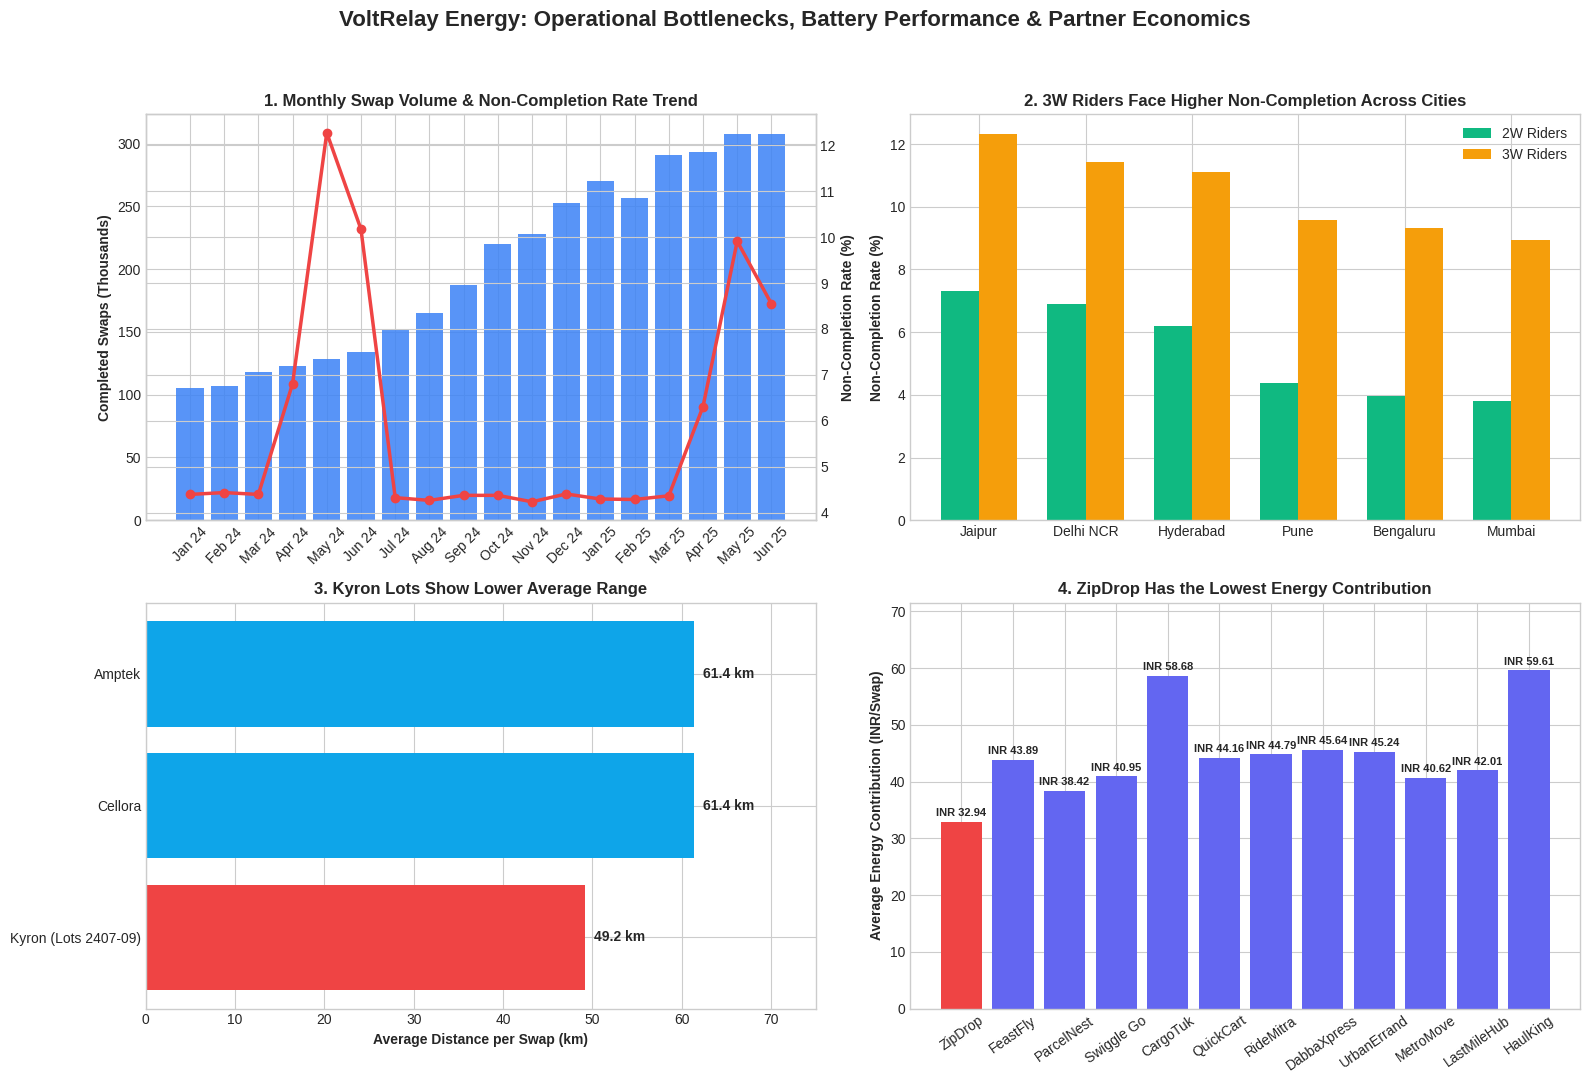

In [37]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# EXECUTIVE VISUAL SUMMARY
# ==========================================

plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    'VoltRelay Energy: Operational Bottlenecks, Battery Performance & Partner Economics',
    fontsize=16,
    fontweight='bold',
    y=0.98
)


# ==========================================
# CHART 1: MONTHLY BUSINESS PERFORMANCE
# ==========================================

ax1 = axes[0, 0]

months = pd.to_datetime(q1_df['month']).dt.strftime('%b %y')

ax1.bar(
    months,
    q1_df['completed_swaps'] / 1000,
    color='#3b82f6',
    alpha=0.85
)

ax1.set_ylabel('Completed Swaps (Thousands)', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

ax1_twin = ax1.twinx()

ax1_twin.plot(
    months,
    q1_df['failure_rate_pct'],
    color='#ef4444',
    marker='o',
    linewidth=2.5
)

ax1_twin.set_ylabel(
    'Non-Completion Rate (%)',
    fontweight='bold'
)

ax1.set_title(
    '1. Monthly Swap Volume & Non-Completion Rate Trend',
    fontweight='bold'
)


# ==========================================
# CHART 2: CITY-WISE 2W VS 3W COMPARISON
# ==========================================

q2_chart = con.execute(f"""
    SELECT
        st.city,
        r.vehicle_class,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN s.event_type != 'swap_completed'
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS non_completion_pct

    FROM swaps s

    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id

    JOIN '{DATA_PATH}/riders.csv' r
        ON s.rider_id = r.rider_id

    GROUP BY st.city, r.vehicle_class

""").df()

q2_chart = q2_chart.pivot(
    index='city',
    columns='vehicle_class',
    values='non_completion_pct'
).sort_values('3W', ascending=False)


ax2 = axes[0, 1]

x = np.arange(len(q2_chart.index))

ax2.bar(
    x - 0.18,
    q2_chart['2W'],
    width=0.36,
    label='2W Riders',
    color='#10b981'
)

ax2.bar(
    x + 0.18,
    q2_chart['3W'],
    width=0.36,
    label='3W Riders',
    color='#f59e0b'
)

ax2.set_xticks(x)
ax2.set_xticklabels(q2_chart.index)

ax2.set_ylabel(
    'Non-Completion Rate (%)',
    fontweight='bold'
)

ax2.set_title(
    '2. 3W Riders Face Higher Non-Completion Across Cities',
    fontweight='bold'
)

ax2.legend()


# ==========================================
# CHART 3: BATTERY LOT-WISE RANGE COMPARISON
# ==========================================

q4_chart = con.execute(f"""
    SELECT

        CASE
            WHEN b.supplier = 'Kyron'
                 AND b.manufacturing_lot IN (
                     'KY-2407',
                     'KY-2408',
                     'KY-2409'
                 )
            THEN 'Kyron (Lots 2407-09)'

            ELSE b.supplier
        END AS cohort,

        ROUND(
            AVG(s.km_since_last_swap),
            1
        ) AS avg_km

    FROM swaps s

    JOIN '{DATA_PATH}/batteries.csv' b
        ON s.battery_in_id = b.battery_id

    WHERE s.event_type = 'swap_completed'
      AND b.pack_type = '2W_2.1kWh'
      AND b.supplier IN ('Kyron', 'Cellora', 'Amptek')

    GROUP BY 1
    ORDER BY avg_km ASC

""").df()


ax3 = axes[1, 0]

colors_c3 = [
    '#ef4444' if 'Kyron' in c else '#0ea5e9'
    for c in q4_chart['cohort']
]

bars3 = ax3.barh(
    q4_chart['cohort'],
    q4_chart['avg_km'],
    color=colors_c3
)

ax3.set_xlabel(
    'Average Distance per Swap (km)',
    fontweight='bold'
)

ax3.set_title(
    '3. Kyron Lots Show Lower Average Range',
    fontweight='bold'
)

ax3.set_xlim(0, 75)

for bar in bars3:
    ax3.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width()} km",
        va='center',
        fontweight='bold'
    )


# ==========================================
# CHART 4: PARTNER-WISE ENERGY CONTRIBUTION
# ==========================================

q5_chart = con.execute(f"""
    SELECT
        fp.partner_name,

        COUNT(s.event_id) AS completed_swaps,

        ROUND(
            AVG(
                s.amount_charged_inr
                - s.energy_to_recharge_kwh
                  * st.grid_tariff_inr_kwh
            ),
            2
        ) AS avg_energy_contribution

    FROM swaps s

    JOIN '{DATA_PATH}/riders.csv' r
        ON s.rider_id = r.rider_id

    JOIN '{DATA_PATH}/fleet_partners.csv' fp
        ON r.partner_id = fp.partner_id

    JOIN '{DATA_PATH}/stations.csv' st
        ON s.station_id = st.station_id

    WHERE s.event_type = 'swap_completed'

    GROUP BY fp.partner_name

    ORDER BY completed_swaps DESC

""").df()


ax4 = axes[1, 1]

colors_c4 = [
    '#ef4444' if p == 'ZipDrop' else '#6366f1'
    for p in q5_chart['partner_name']
]

bars4 = ax4.bar(
    q5_chart['partner_name'],
    q5_chart['avg_energy_contribution'],
    color=colors_c4
)

ax4.set_ylabel(
    'Average Energy Contribution (INR/Swap)',
    fontweight='bold'
)

ax4.set_title(
    '4. ZipDrop Has the Lowest Energy Contribution',
    fontweight='bold'
)

ax4.tick_params(axis='x', rotation=35)

ax4.set_ylim(
    0,
    max(q5_chart['avg_energy_contribution']) * 1.2
)

for bar in bars4:
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"INR {bar.get_height():.2f}",
        ha='center',
        fontweight='bold',
        fontsize=8
    )


# ==========================================
# FINAL LAYOUT
# ==========================================

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()
